---
title: "Perception"
---

## Lecture 2 Automotive sensors

This contains only the notes that was mentioned that should be studied. However the levels of automated driving is also added.
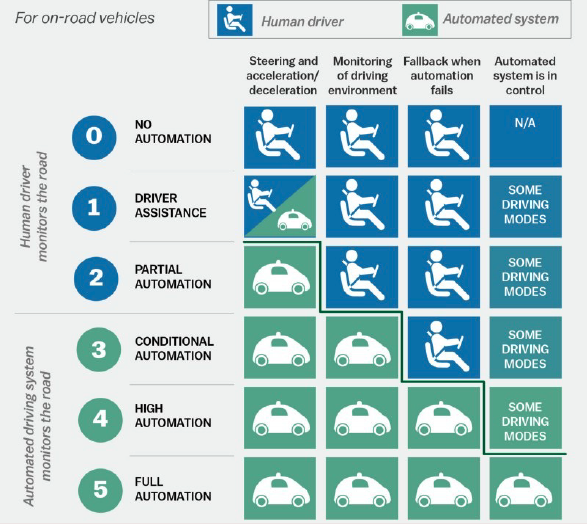
Also just to be sure some types of sensors. 
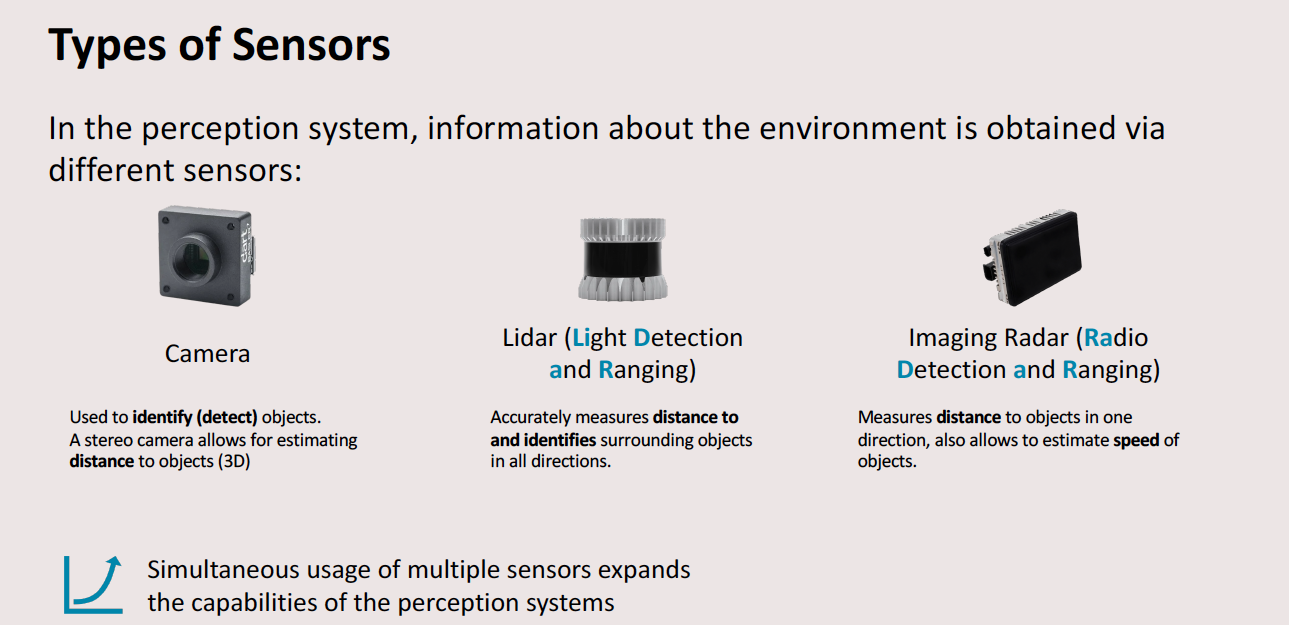

### Types of analysis


**Classification:**
- Determine class of the object within its general category 

**Detection:** 
- Find the location of objects from a general category in sensor data

**Ranging:**
- Estimate distance of a detected object

**Recognition:**
- Find exactly the same object instance in sensor data

**Tracking:**
- Estimate (and predict) path of a detected object
- Recognition over time 

### Metrics 

#### Precision
precision is the percentage of correct detections.
$$
Prec = \frac{TP}{TP+FP}
$$

#### Recall
Recall is the percentage of how many of the postives it could find out of the dataset
$$
Rec= \frac{TP}{TP + FN}
$$

#### F1-score
The F1-score is a trade off between precision and recall
$$
F_1 = \frac{2}{\frac{1}{Rec}+\frac{1}{Prec}}= \frac{2*Rec*Prec}{Rec+Prec} = \frac{2|TP|}{2|TP|+|FP|+|FN|}
$$

## Lecture 3 Introduction to deep learning


When the feature computation and classifier are designed manually this is also called model-based. Which has various problems like occlusions, lighting etc. In deep learning the feature computation and the classifier are trained. It is now data-driven

Some activation functions are given below:

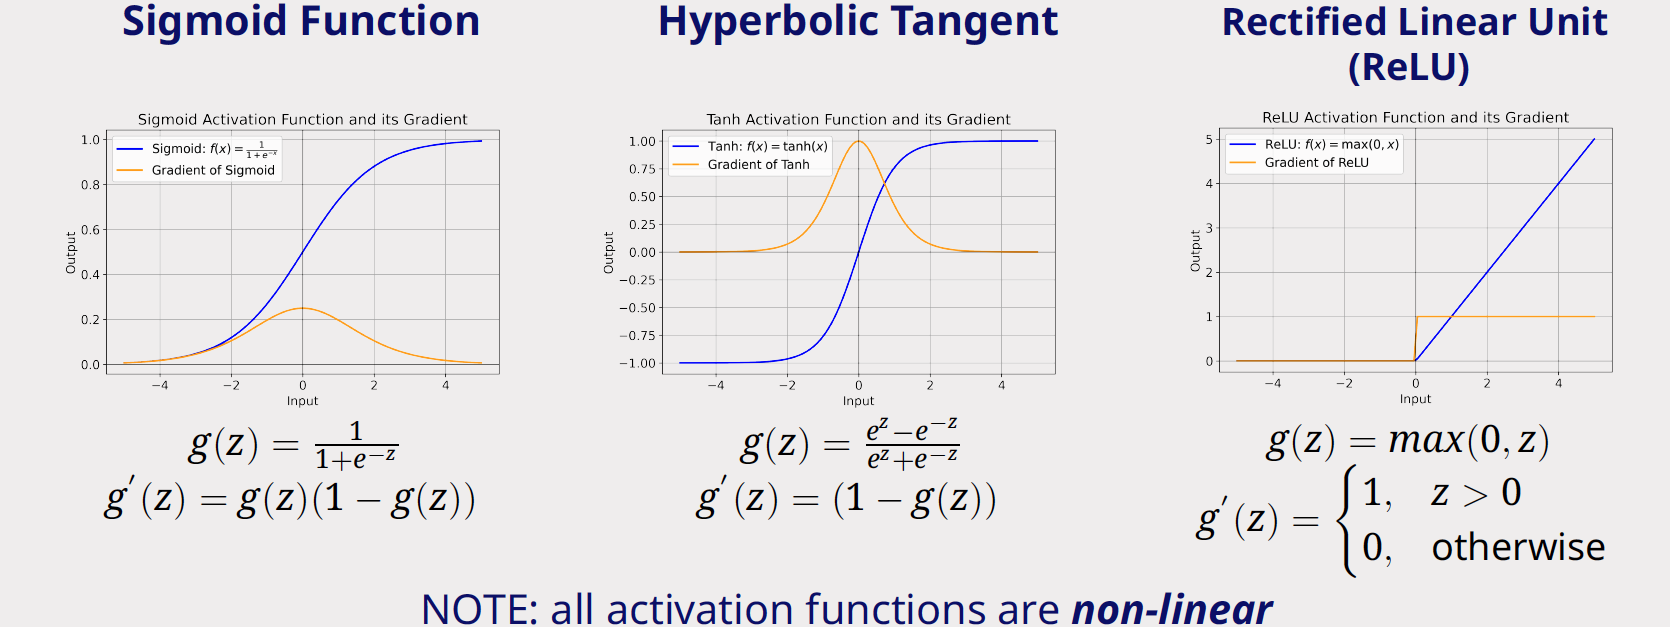

The binary cross entropy loss is given by:
$$
 \lambda = y \cdot log(f(x)) + (1-y) \cdot log(1-f(x))
$$

Overfitting can be reduced by using L2 Regularization (Frobenius norm), this just the same as ridge idk why it is called like that.
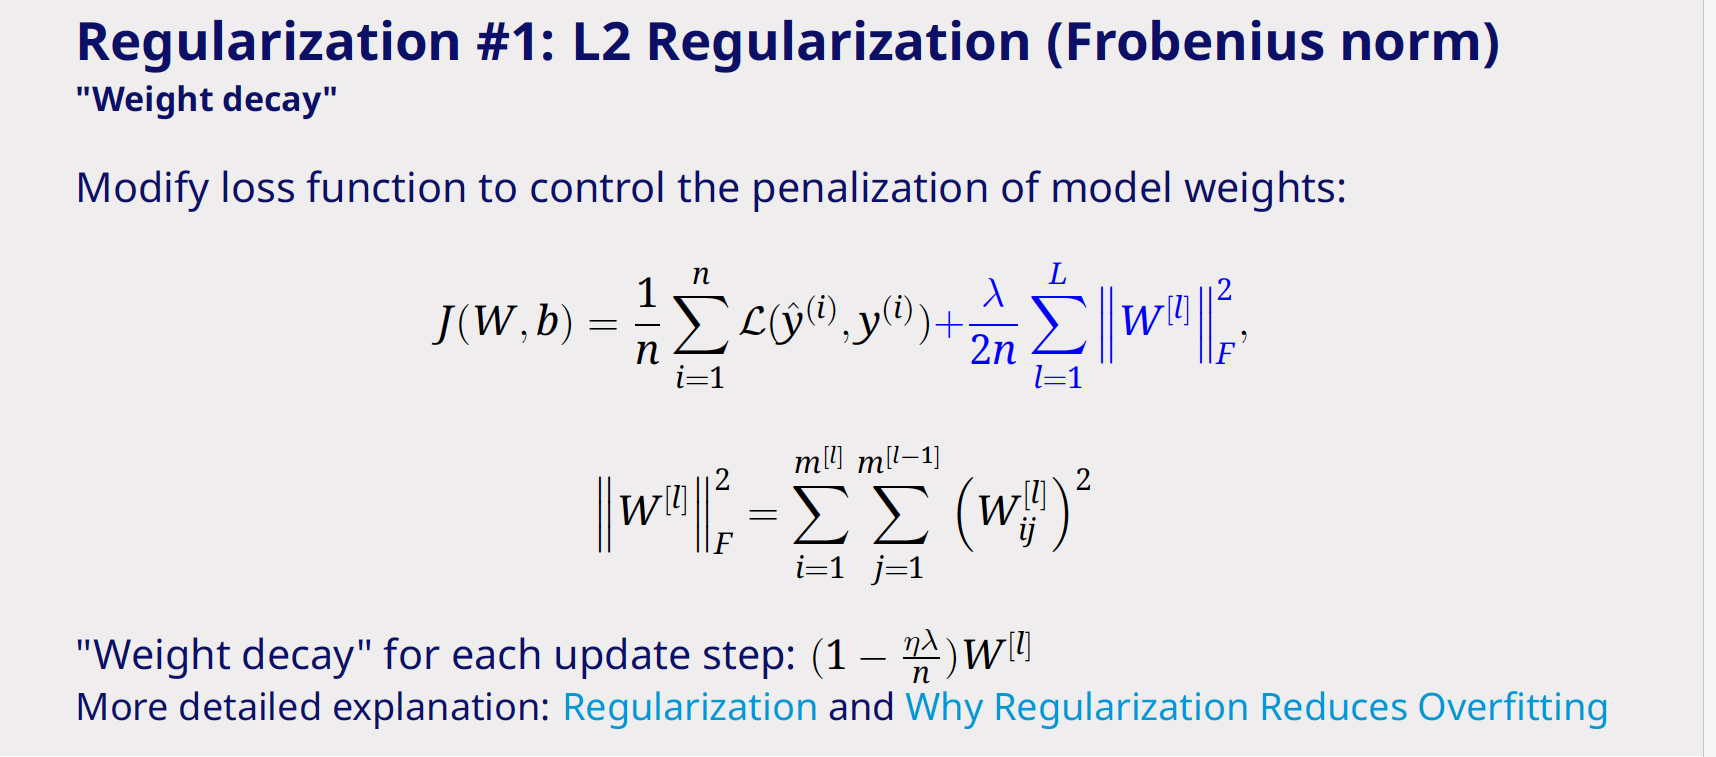

Methods to reduce overfitting are:
- Dropout
- Regularization
- Early stopping

## Lecture 4 Limitations of datasets & object detection


Any dataset always represents a limited view on / only a sample of on the real world and therefore hard to generalize. Therefore partly data augmentation exists, one of these is shearing in which you hold the axis perpendiculr but place the corner of the image in a different position. This way you simulate camera angles and such. 


The pooling operation has the following results:
- Promotes dominat features
- introduces translational invariance
-Suppresses noise
- reduces dimensionality

The softmax function is given as:
$$
softmax(y)=\frac{e^y}{\sum e^y}
$$

In detection you want to have the follwing output vector:
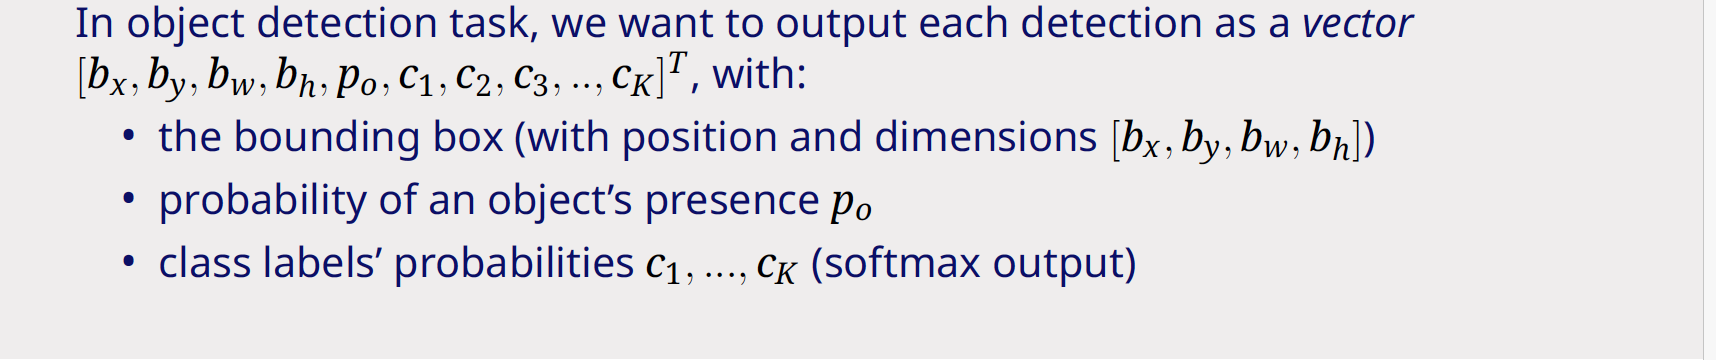

However it is difficult to predict:
- different absolute positsions of objects 
- different shapes (aspect ratio) of objects that may also overlay

Therefore it is easier to predict an offset in position and size relative to a predefined, reference bounding (anchor) box. So you get:

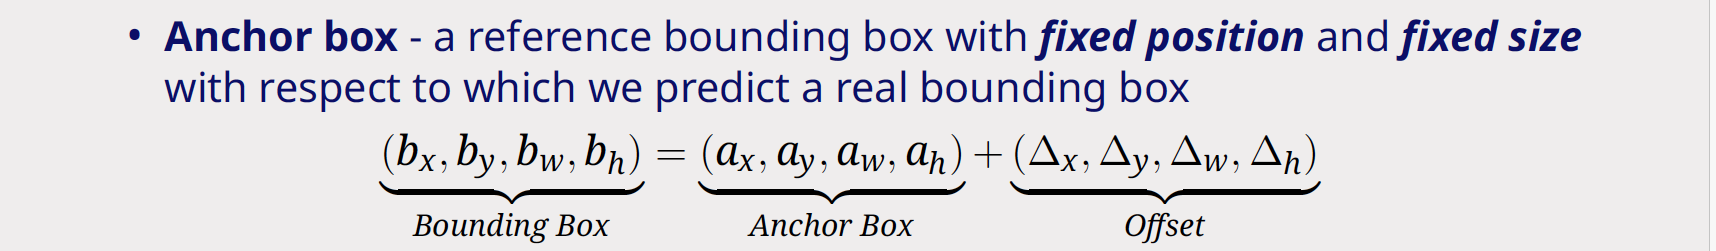

Mostly DNN networks contain 3 components:
- region proposals
- Network predictions using feature extraction
- Non-maximum suppressions (cleaning up)

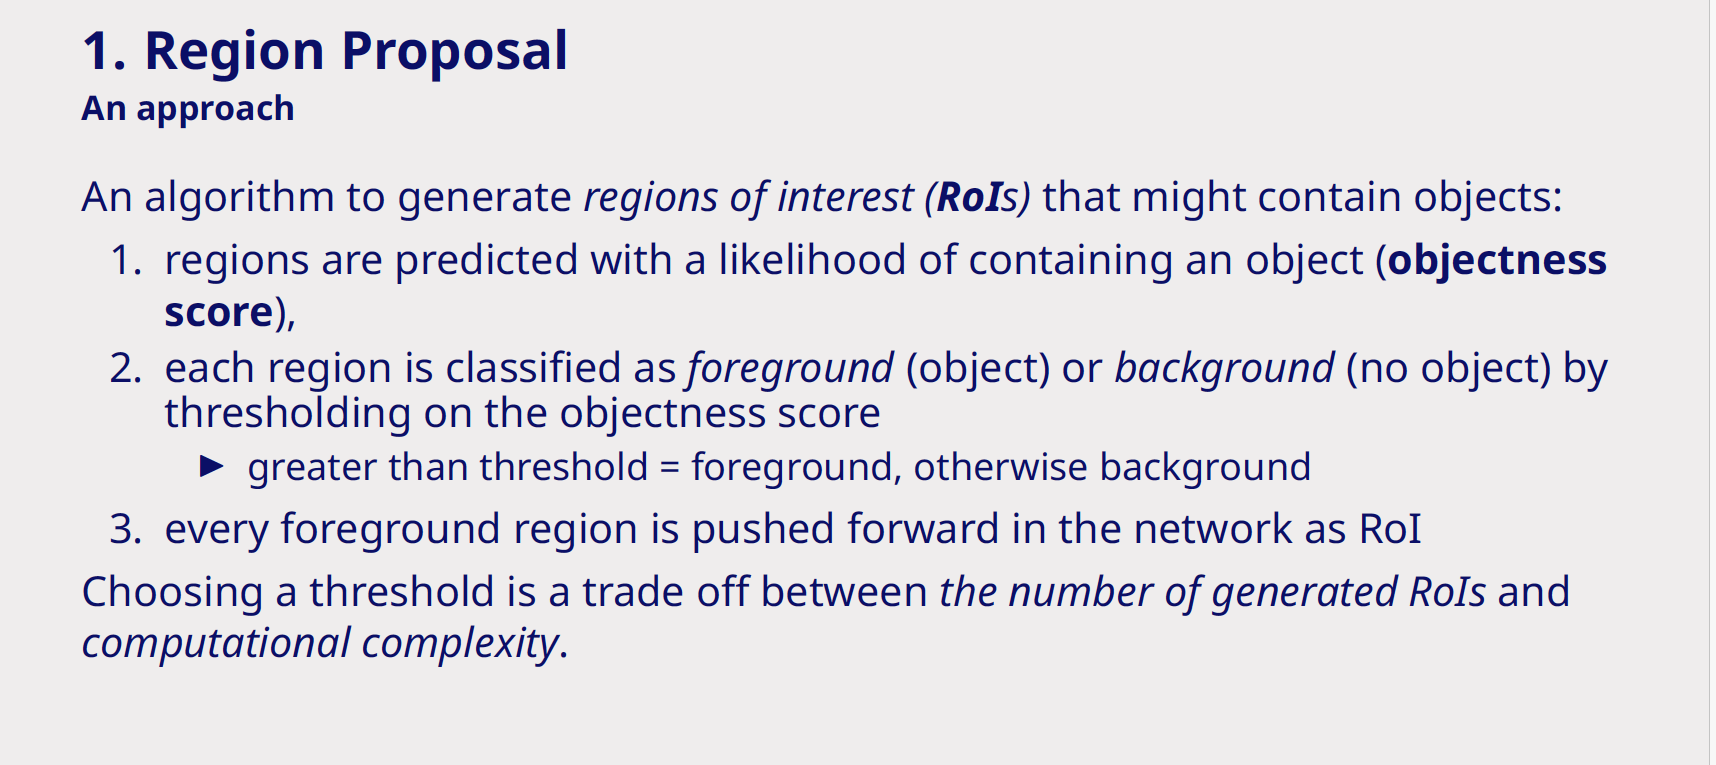

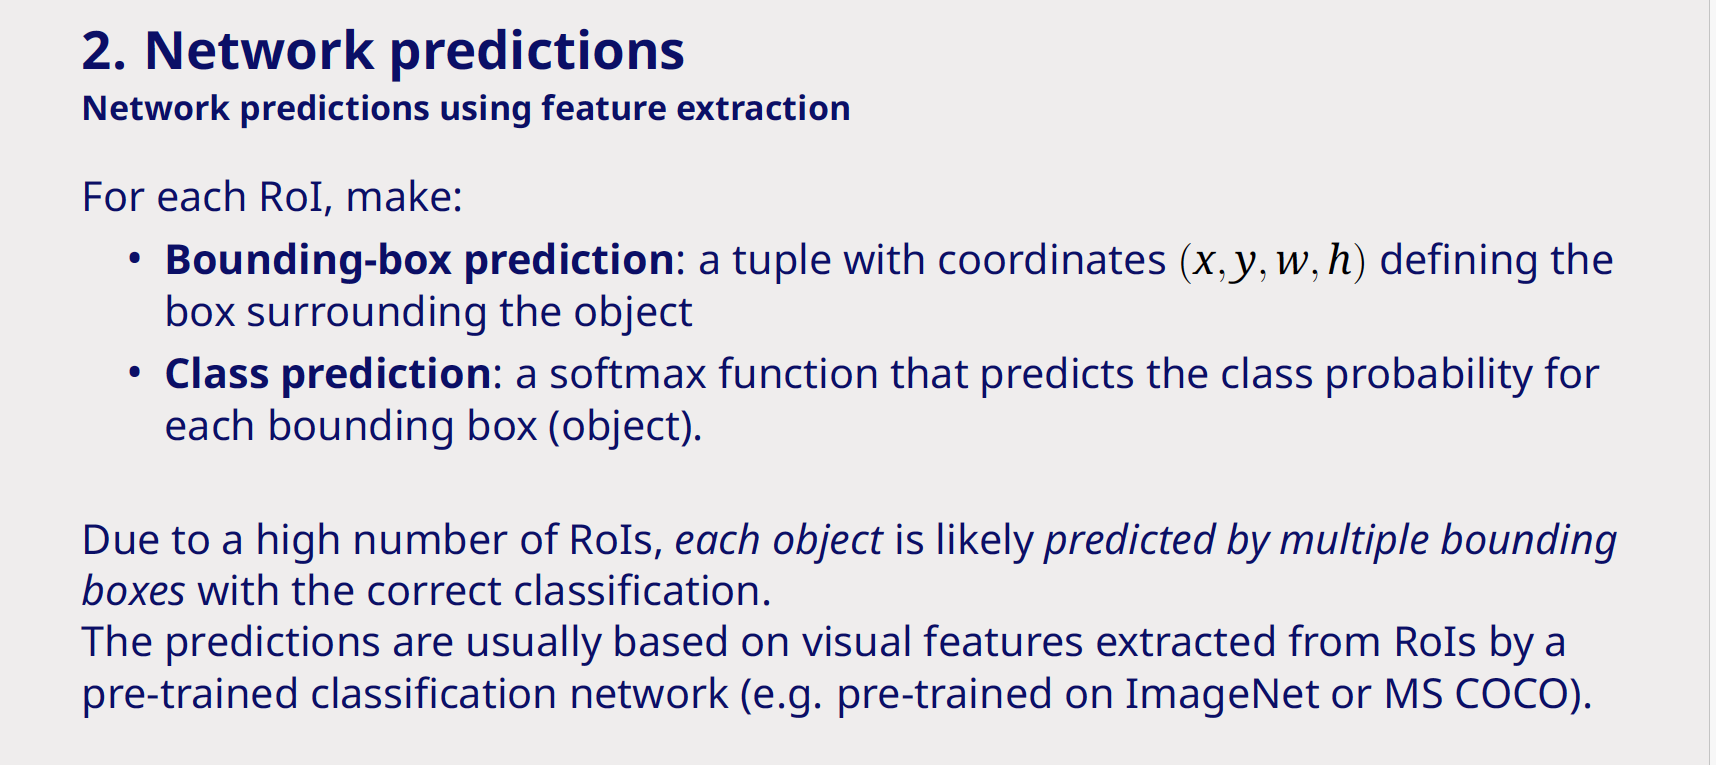

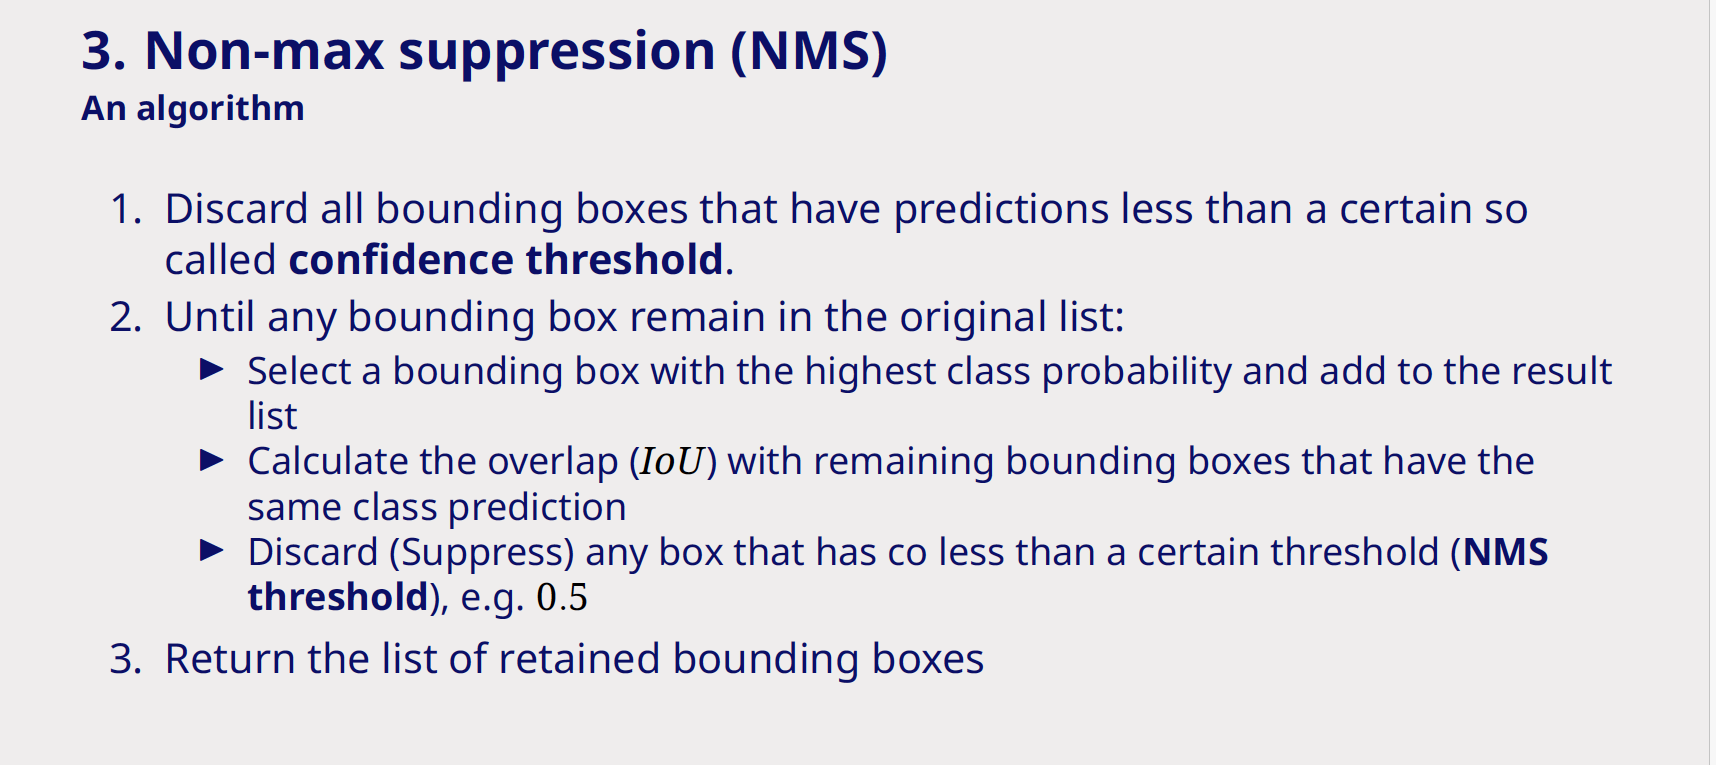

### Evaluation metrics

#### IoU 
Intersection over union.
$$
\text{IoU}(B_P, B_{GT}) = J(B_P, B_{GT}) = \frac{|B_P \cap B_{GT}|}{|B_P \cup B_{GT}|}
$$

Where:
* **$B_P$**: Predicted Bounding Box
* **$B_{GT}$**: Ground Truth Bounding Box
* **$B_P \cap B_{GT}$**: Area of Overlap (Intersection)
* **$B_P \cup B_{GT}$**: Area of Encompassed Region (Union)

#### Average precision
this is the area under the precision-recall curve. 
$$AP = \int_{r=0}^{1} p(r) \, dr$$
in which p(r) is based on the confidence threshold


#### Mean average precision
This is the same as the average precision but now the mean is taken over the classes
$$
mAP= \frac{1}{K}= \sum^K_{c=1}AP(c)
$$

You can calculate the mAP for different levels of IoU threshold. Then we get e.g. mAP@0.5, mAP@0.75, which is also noted as $AP_{50}$. Sometimes mAP is reported as the mean of mAP over different IoU thresholds. mAP@[.50:.95] or mAP@[.50:.05:.95]

### Yolo detction 

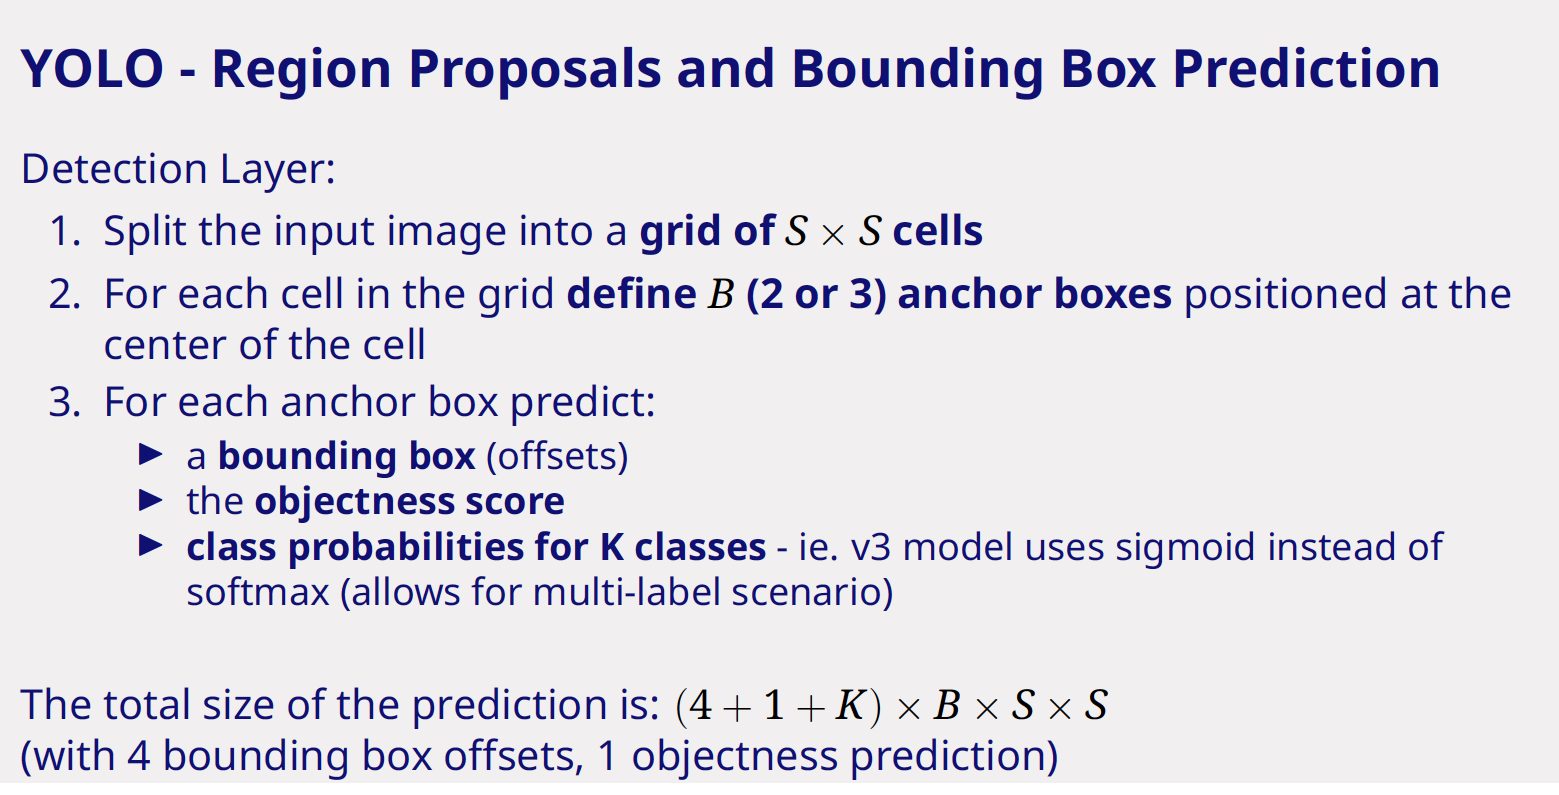

To predict different scales of the objects, we. eploy girds of different sizes.

## Lecture 5 Object detection with lidar

3D data has other challengens:
- Amount of data is much higher therefore real-time processing is more demanding
- 3D point cloud data is irregular/ non-uniform / unstructured
- No fixed grid compared to 2D grid of pixels i images -> point $n$ can be anywhere in 3D space
- Occlusions (objects cast 'shadow')

the 3d data can be represented using:
- point-based
- voxel-based
- pillar-based (basically voxel-based except that each pillar does have unlimited height)
- Graph-based
- projection-based (Front view or also called range view) 
- projection-based (Birds eye view)



### Data representations overview


#### Point-based
Keeps unstructured form however is often down-sampled to a fixed size of N points.


#### Voxel-based
The 3d space is partitioned into voxels, points are assigned to voxels. It can be done in 3 ways:
- fixed voxelization
- dynamic voxelization
- hybrid scale voxelization (uses various sizes of voxels)

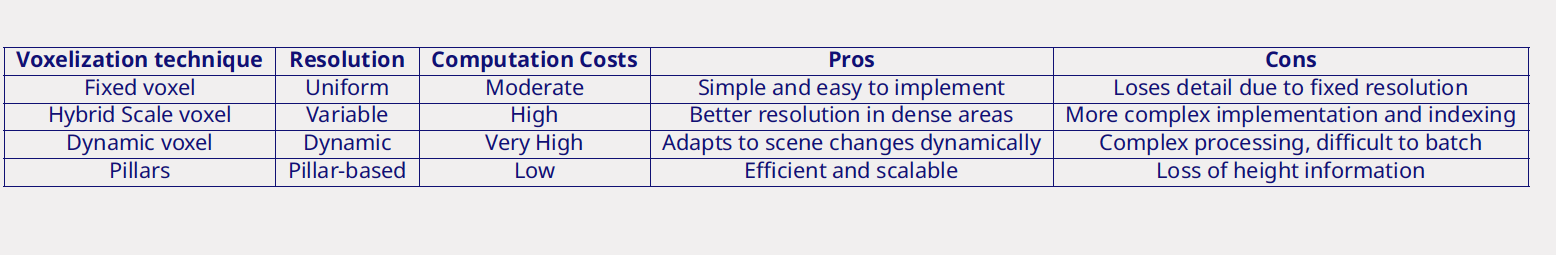

#### Projection based (Front view - Spherical)
Basically what you do is that you map a point from x,y,z into speherical coordinate representation and then unroll this sphere into a 2d map. The radar is supposed to be the middle of the sphere.
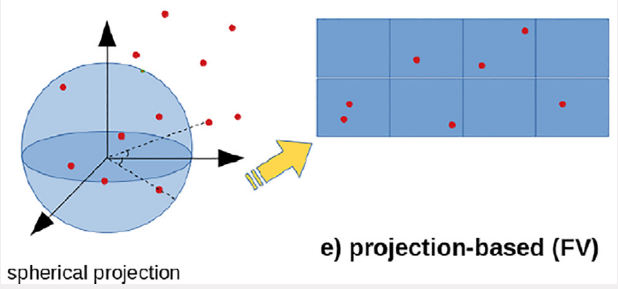

$$
\begin{aligned}
\text{Azimuth } \phi_i &= arctan(\frac{y_i}{x_i})\\
\text{Polar / elevation } \theta_i &= arccos(\frac{z_i}{r_i})\\
\text{radial distance } r_i &= \sqrt{x_i^2 + y_i^2 + z_i^2}
\end{aligned}
$$

#### Projection based (cylindrical)
Is basically the same but now the coordinates are in cylindrical instead of spherical.


#### Projection birds eye view
The points are mapped into 2d with grid size $\lambda$ 

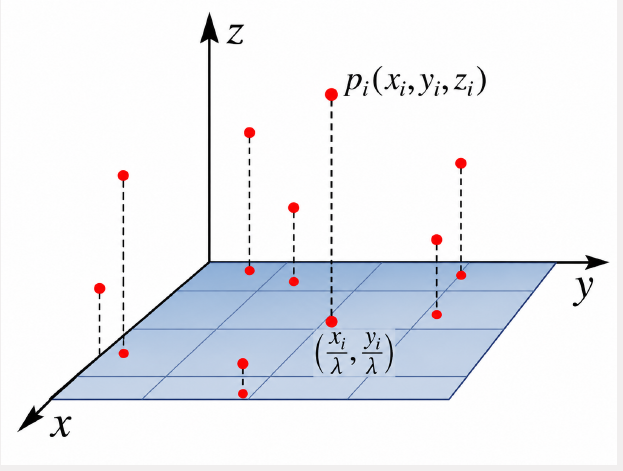

#### Evaluation on performance metrics

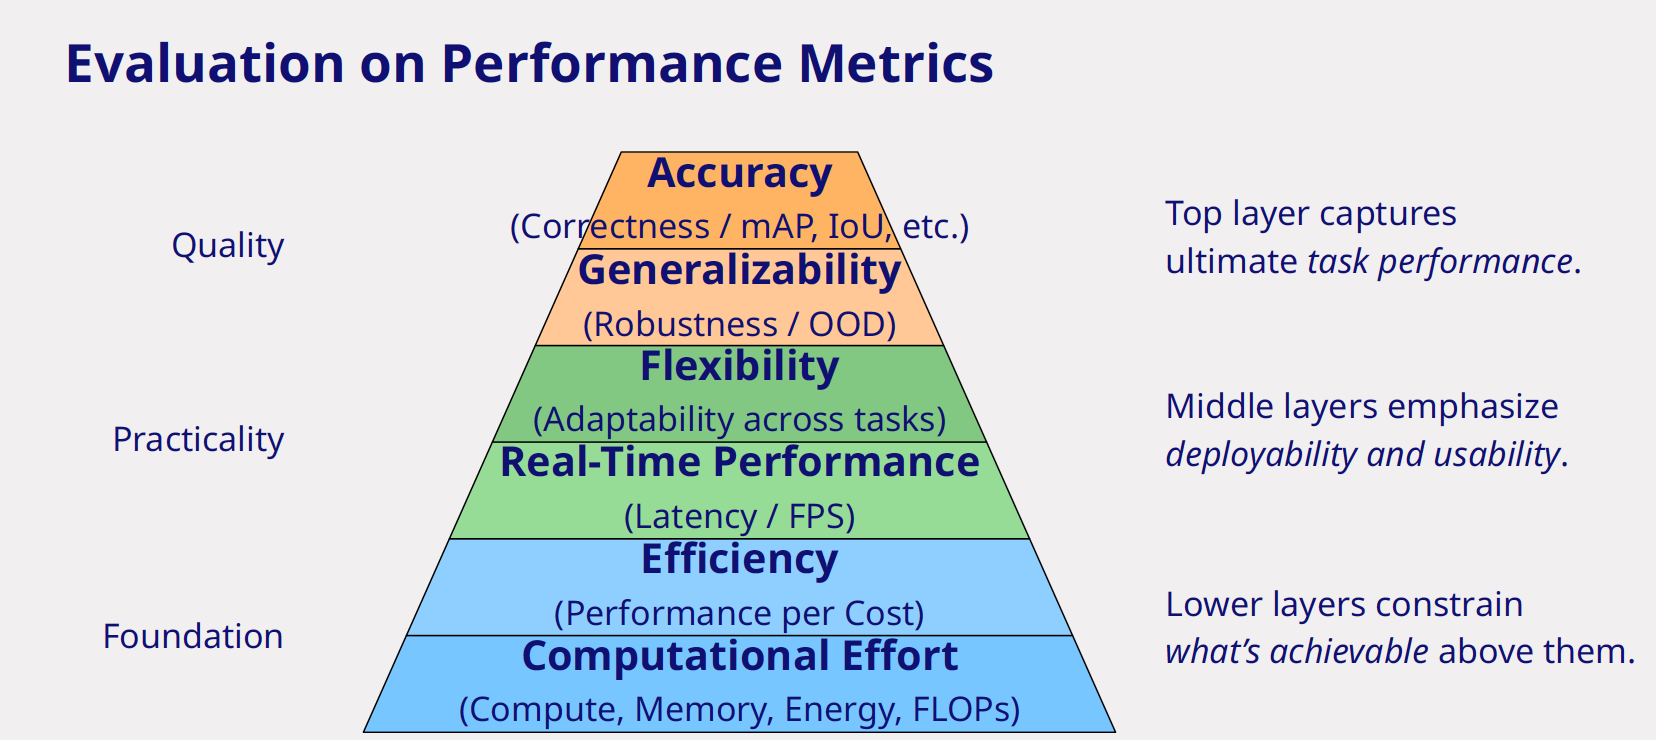

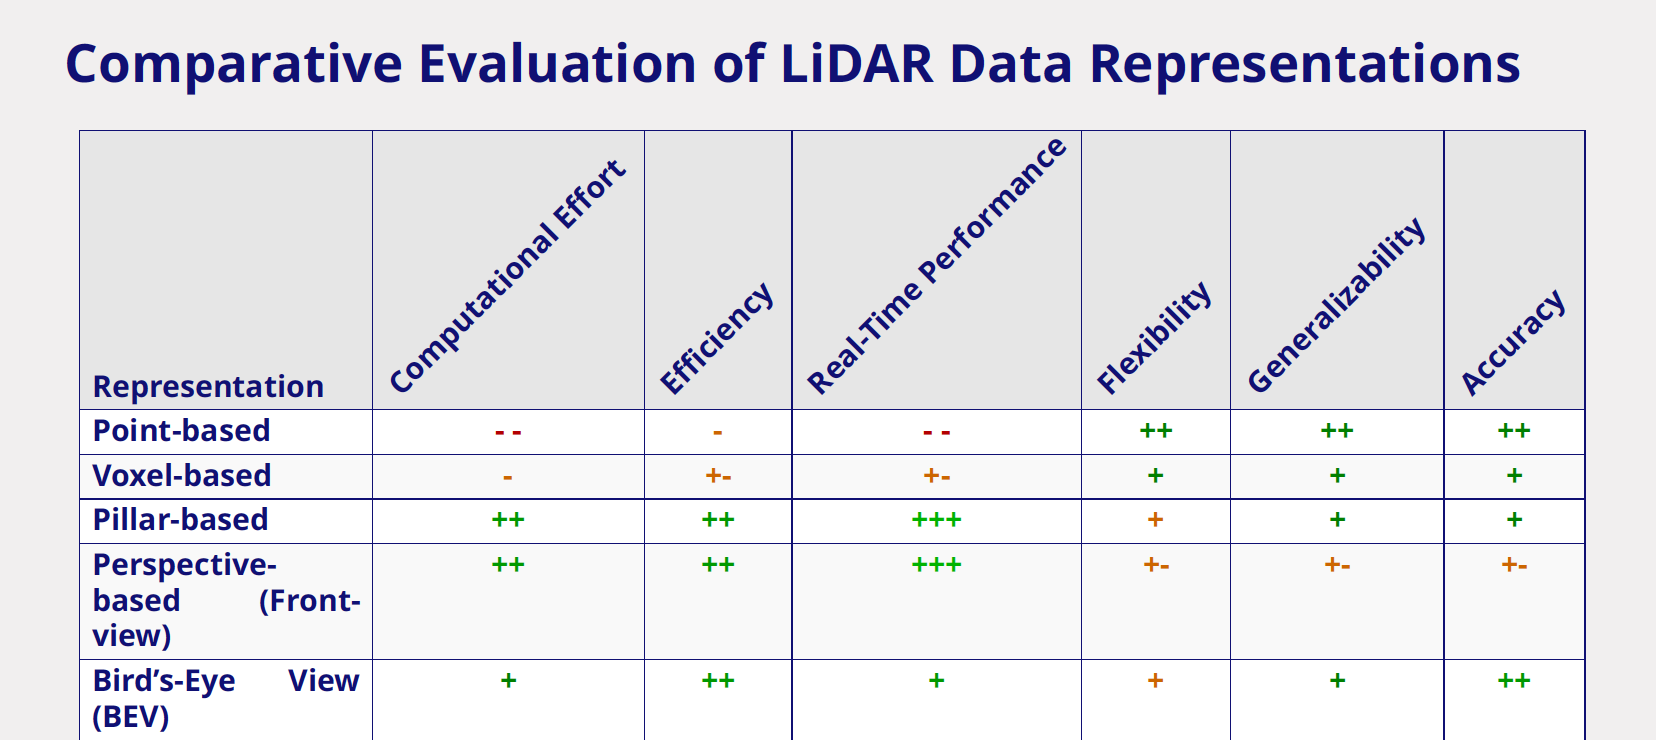

### Feature extraction

A 3D CNN network can work completely the same on a voxel instead of an image. However this comes at a high computational load therefore not useful in real time applications. 

### Core object detection

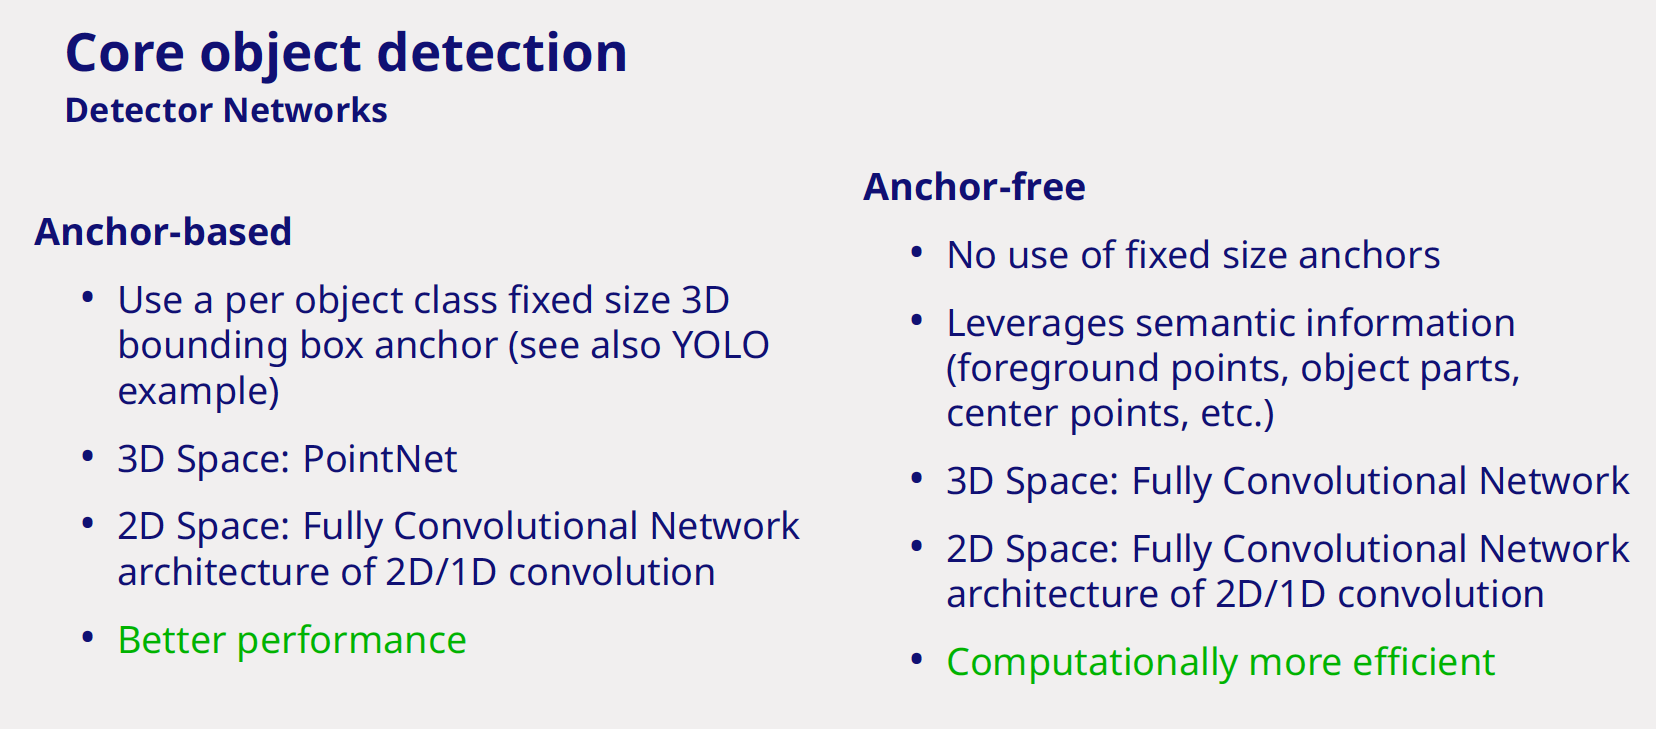

### Pointpillars

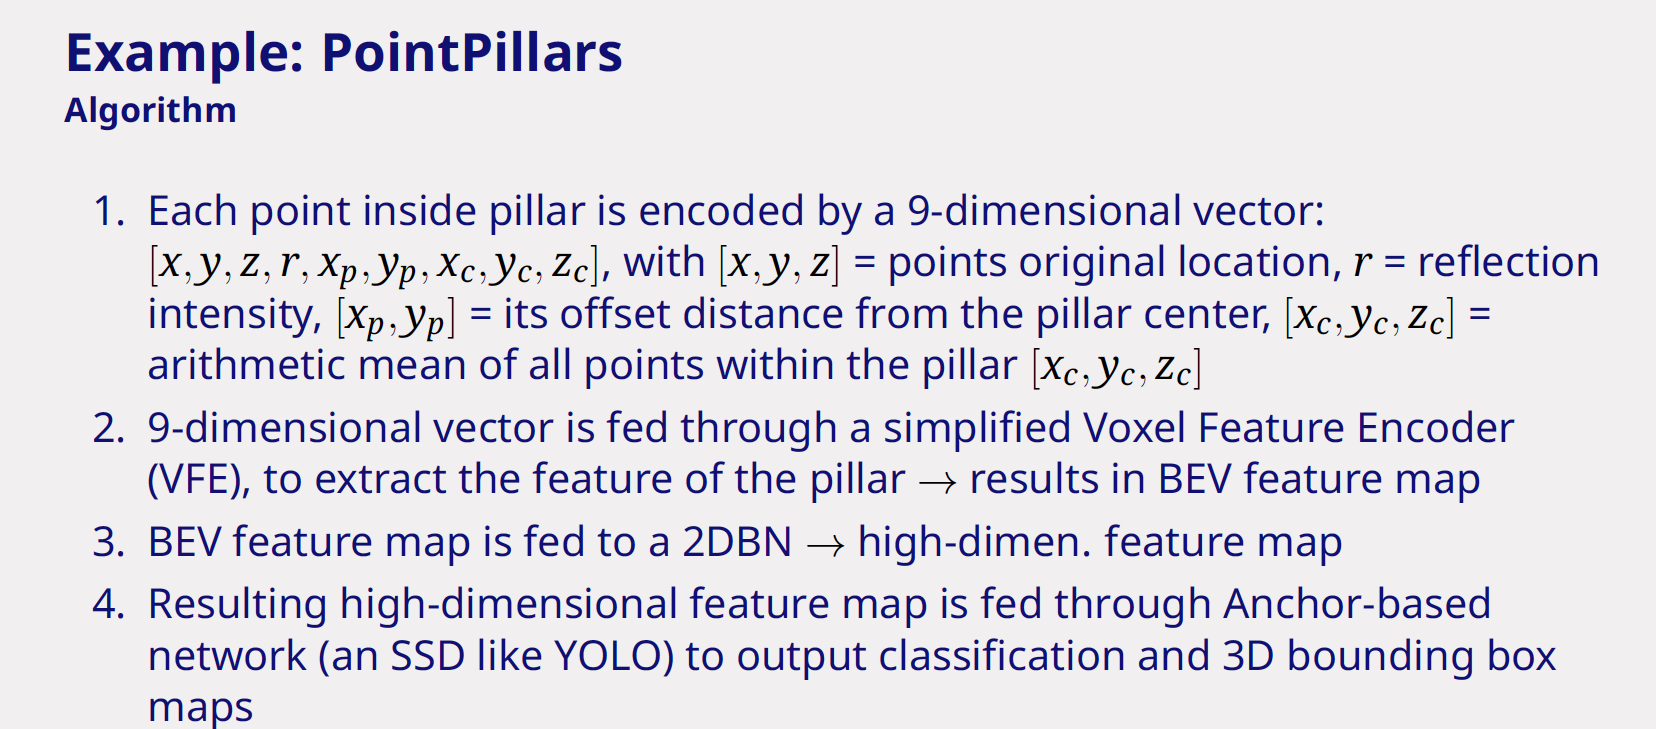